# 08 · Exploratory: time-series trend and curve carry on futures

> **EXPLORATORY, NOT THE BINDING VERDICT.** These two strategies were chosen *after* the binding mean-reversion verdict was seen (all three spreads FAIL G1–G5 on futures). Their rules were registered in `PREREGISTRATION_TREND_CARRY.md` and `config.yaml` → `exploratory_trend_carry` on 2026-10-28, before any trend or carry number was computed, and `tests/test_preregistration.py` guards them. Nothing here changes the mean-reversion verdict, and no registered value may be changed because of what this notebook shows.

| | Strategy 1: trend (Moskowitz, Ooi & Pedersen 2012) | Strategy 2: carry (Koijen, Moskowitz, Pedersen & Vrugt 2018) |
|---|---|---|
| Instruments | Outrights CL, CO, XB, HO; spreads 3-2-1 crack, Brent–WTI, HO−RB | Outrights CL, CO |
| Signal at close t | sign of the 252-day change in the back-adjusted price | sign of M1 − M2 (held month minus next; + backwardation → long) |

**Common rules.**
- **Sizing:** units = sign × R / (σ̂ × M), with R = \$6k a day per instrument and σ̂ the point-in-time GARCH(1,1)-t forecast, refit monthly on 756 days. Units are unrounded and resized daily.
- **Timing and costs:** decide at close t and fill at close t+1. Costs are \$0.05/bbl × M per unit of position change, plus 1 tick per contract leg on each roll.
- **Books:** each sleeve is the equal-risk average of its instruments; the combined book is 0.5 × trend + 0.5 × carry.

**Code:** `src/oilrv/trend_carry.py` and `scripts/run_trend_carry.py`. **Outputs:** `output/exploratory/trend_carry/` and `data/derived/exploratory/trend_carry_daily.csv`.

In [1]:
import json
import numpy as np
import pandas as pd
from IPython.display import Image
from oilrv.config import ROOT
import sys; sys.path.insert(0, str(ROOT / 'scripts'))
import run_trend_carry
summary = run_trend_carry.main()             # about 25 s
D = ROOT / 'output/exploratory/trend_carry'
T, F = D / 'tables', D / 'figures'
read = lambda n, **k: pd.read_csv(T / n, **k)
pd.set_option('display.width', 200)
print(summary['status']); print('trading', summary['start'], '→', summary['end'])

EXPLORATORY (PREREGISTRATION_TREND_CARRY.md); does not change the binding verdict
trading 2010-02-01 → 2026-10-26


## Gate verdicts (G1–G5), on the combined book and per sleeve

In [2]:
v = summary['verdicts']
tick = lambda b: '✓' if b else '✗'
pd.DataFrame({k: {'G1 Sharpe > 0.5': f"{d['G1_value']:.2f} {tick(d['G1_sharpe'])}",
                  'G2 position changes ≥ 20': f"{d['G2_value']} {tick(d['G2_changes'])}",
                  'G3 sub-periods > 0 (≥ 2 of 3)': f"{d['G3_value']} {tick(d['G3_subperiods'])}",
                  'G4 grid all > 0': ' / '.join(f'{x:.2f}' for x in d['G4_value'].values()) + ' ' + tick(d['G4_grid']),
                  'G5 2022 & 2026 > −$40k': ' / '.join(f'{x/1e3:+.0f}k' for x in d['G5_value'].values()) + ' ' + tick(d['G5_stress']),
                  'VERDICT': 'PASS' if d['PASS'] else 'FAIL'} for k, d in v.items()}).T

,G1 Sharpe > 0.5,G2 position changes ≥ 20,G3 sub-periods > 0 (≥ 2 of 3),G4 grid all > 0,G5 2022 & 2026 > −$40k,VERDICT
combined,0.45 ✗,1150 ✓,3 ✓,0.33 / 0.45 / 0.52 / 0.45 / 0.46 / 0.45 ✓,+117k / +223k ✓,FAIL
trend,0.29 ✗,971 ✓,3 ✓,0.05 / 0.29 / 0.47 ✓,+150k / +234k ✓,FAIL
carry,0.44 ✗,179 ✓,2 ✓,0.44 / 0.46 / 0.45 ✓,+83k / +212k ✓,FAIL


**FAIL, as a near miss.**
- **Combined book:** net Sharpe **0.45** against the 0.5 bar, so it fails G1. It passes G2–G5: 1,150 position changes, all three sub-periods positive, every grid point positive, and **+\$117k in 2022 and +\$223k in 2026**, the two years in which the mean-reversion strategy lost.
- **Each sleeve:** trend (0.29) and carry (0.44) also fail only G1.
- **Statistical strength:** the t-statistic is 1.83 over 16.7 years, short of conventional significance.

## The books

In [3]:
read('summary_books.csv', index_col=0).round(3)

,sharpe,sharpe_t,total,ann_mean,ann_sd,max_dd,years
trend,0.289,1.180,292686.653,17507.011,60678.389,-228821.495,16.718
carry,0.445,1.818,627376.501,37526.437,84396.278,-237135.068,16.718
combined,0.447,1.828,460031.577,27516.724,61546.171,-209246.925,16.718


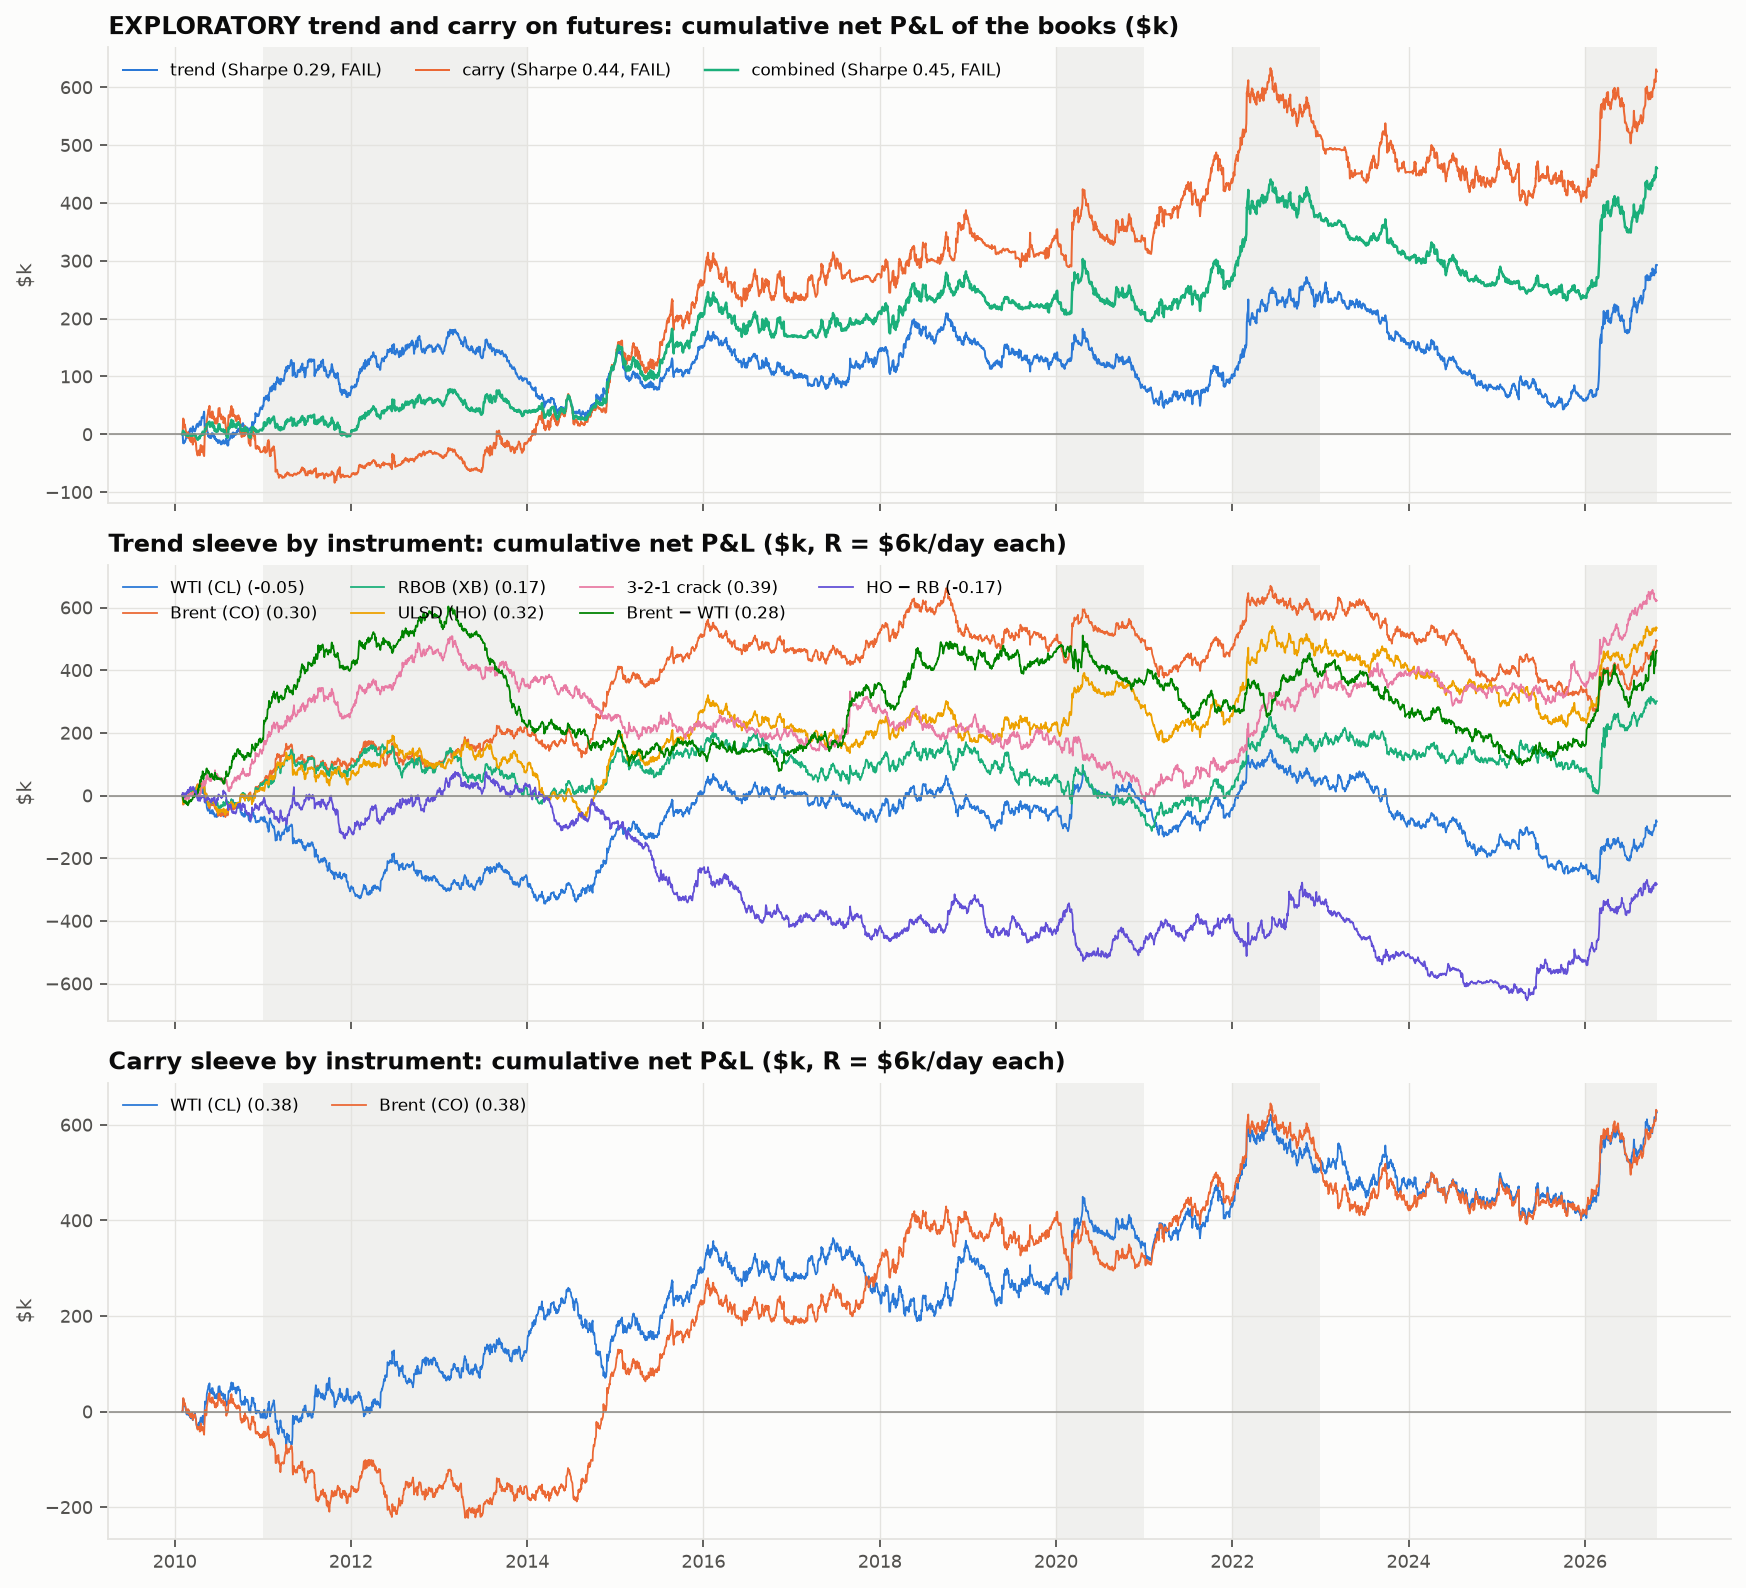

In [4]:
Image(str(F / 'cumulative_pnl.png'))

- **Carry carries the combined book.** Carry alone (0.44) is almost as good as the combined book (0.45). Trend is moderately correlated with carry (0.42) and too weak on its own (0.29) to add much once it takes half the risk.
- **By instrument, carry is uniform and trend is not.** WTI and Brent carry each reach 0.38. Trend works on Brent, ULSD, the crack and Brent–WTI, but loses on WTI and on HO−RB. HO−RB loses even before costs.

In [5]:
i = read('summary_instruments.csv', index_col=0)
i[['sharpe', 'sharpe_t', 'total', 'gross_total', 'cost_total', 'roll_total', 'max_dd', 'position_changes', 'share_days_long']].round(3)

,sharpe,sharpe_t,total,gross_total,cost_total,roll_total,max_dd,position_changes,share_days_long
trend|cl,-0.051,-0.208,-83316.205,15896.353,90276.575,8935.984,-423822.584,150.0,0.471
trend|brent,0.301,1.229,494114.613,596297.336,93127.820,9054.903,-400977.974,151.0,0.586
trend|rb,0.175,0.714,301108.872,375040.151,70794.314,3136.965,-320101.843,143.0,0.607
trend|ho,0.320,1.310,534740.272,601758.336,63841.684,3176.380,-321736.900,119.0,0.565
trend|crack321,0.387,1.582,622372.848,819903.423,175260.994,22269.580,-524132.896,123.0,0.735
trend|brent_wti,0.276,1.127,462397.986,1048064.138,492433.191,93232.962,-525589.361,117.0,0.799
trend|ho_rb,-0.171,-0.701,-282611.817,-107398.224,164616.625,10596.968,-729113.038,168.0,0.428
carry|cl,0.382,1.561,625759.147,692782.124,58086.993,8935.984,-221290.449,74.0,0.451
carry|brent,0.383,1.568,628993.854,707360.173,69311.415,9054.903,-261453.586,105.0,0.666


## Over time: sub-periods (G3) and stress windows (G5 uses 2022 and 2026)

In [6]:
read('subperiods.csv', index_col=[0, 1]).round(2)

net  sharpe    days
book     period                              
trend    2007–2013   92948.57    0.41   988.0
         2014–2019   37325.58    0.11  1511.0
         2020–2026  162412.51    0.36  1714.0
carry    2007–2013  -14513.98   -0.06   988.0
         2014–2019  353279.22    0.70  1511.0
         2020–2026  288611.27    0.44  1714.0
combined 2007–2013   39217.29    0.24   988.0
         2014–2019  195302.40    0.53  1511.0
         2020–2026  225511.89    0.47  1714.0

In [7]:
(read('stress_windows.csv', index_col=0) / 1e3).round(1).add_suffix(' ($k)')

,trend ($k),carry ($k),combined ($k)
brent_wti_break,43.6,14.7,29.2
covid,-49.2,-4.4,-26.8
ukraine,150.2,83.0,116.6
hormuz,233.6,212.0,222.8


- **2010–13:** carry lost (WTI carry +\$133k against Brent carry −\$162k), while trend made money.
- **2014–19:** carry's best period (Sharpe 0.70), mostly from the 2014–15 price collapse, when the curve was in contango and the position short.
- **Stress years:** both sleeves made money in 2022 and 2026, when prices and spreads moved one way for months. That is exactly what broke mean reversion. Trend lost in COVID 2020 (−\$49k).

## Sensitivity: the pre-registered grid (G4)

In [8]:
read('grid.csv', index_col=[0, 1]).round(3)

trend  combined  carry
grid           value                        
trend lookback 126    0.053     0.332    NaN
               252    0.289     0.447    NaN
               504    0.472     0.516    NaN
carry slope    m1_m2    NaN     0.447  0.445
               m1_m3    NaN     0.461  0.464
               m1_m6    NaN     0.452  0.446

- **Every grid point is positive**, so G4 passes.
- **Trend improves with a longer lookback:** 0.05 → 0.29 → 0.47 for 126 / 252 / 504 days. Carry hardly changes with the slope measure (0.44–0.46).
- **The 504-day combined book's 0.52 is not a pass.** Choosing that setting after seeing this table is exactly the overfitting the pre-registration rules out.

## Diagnostics (descriptive, not gated): drawdowns, rolling Sharpe, calendar years, grid paths

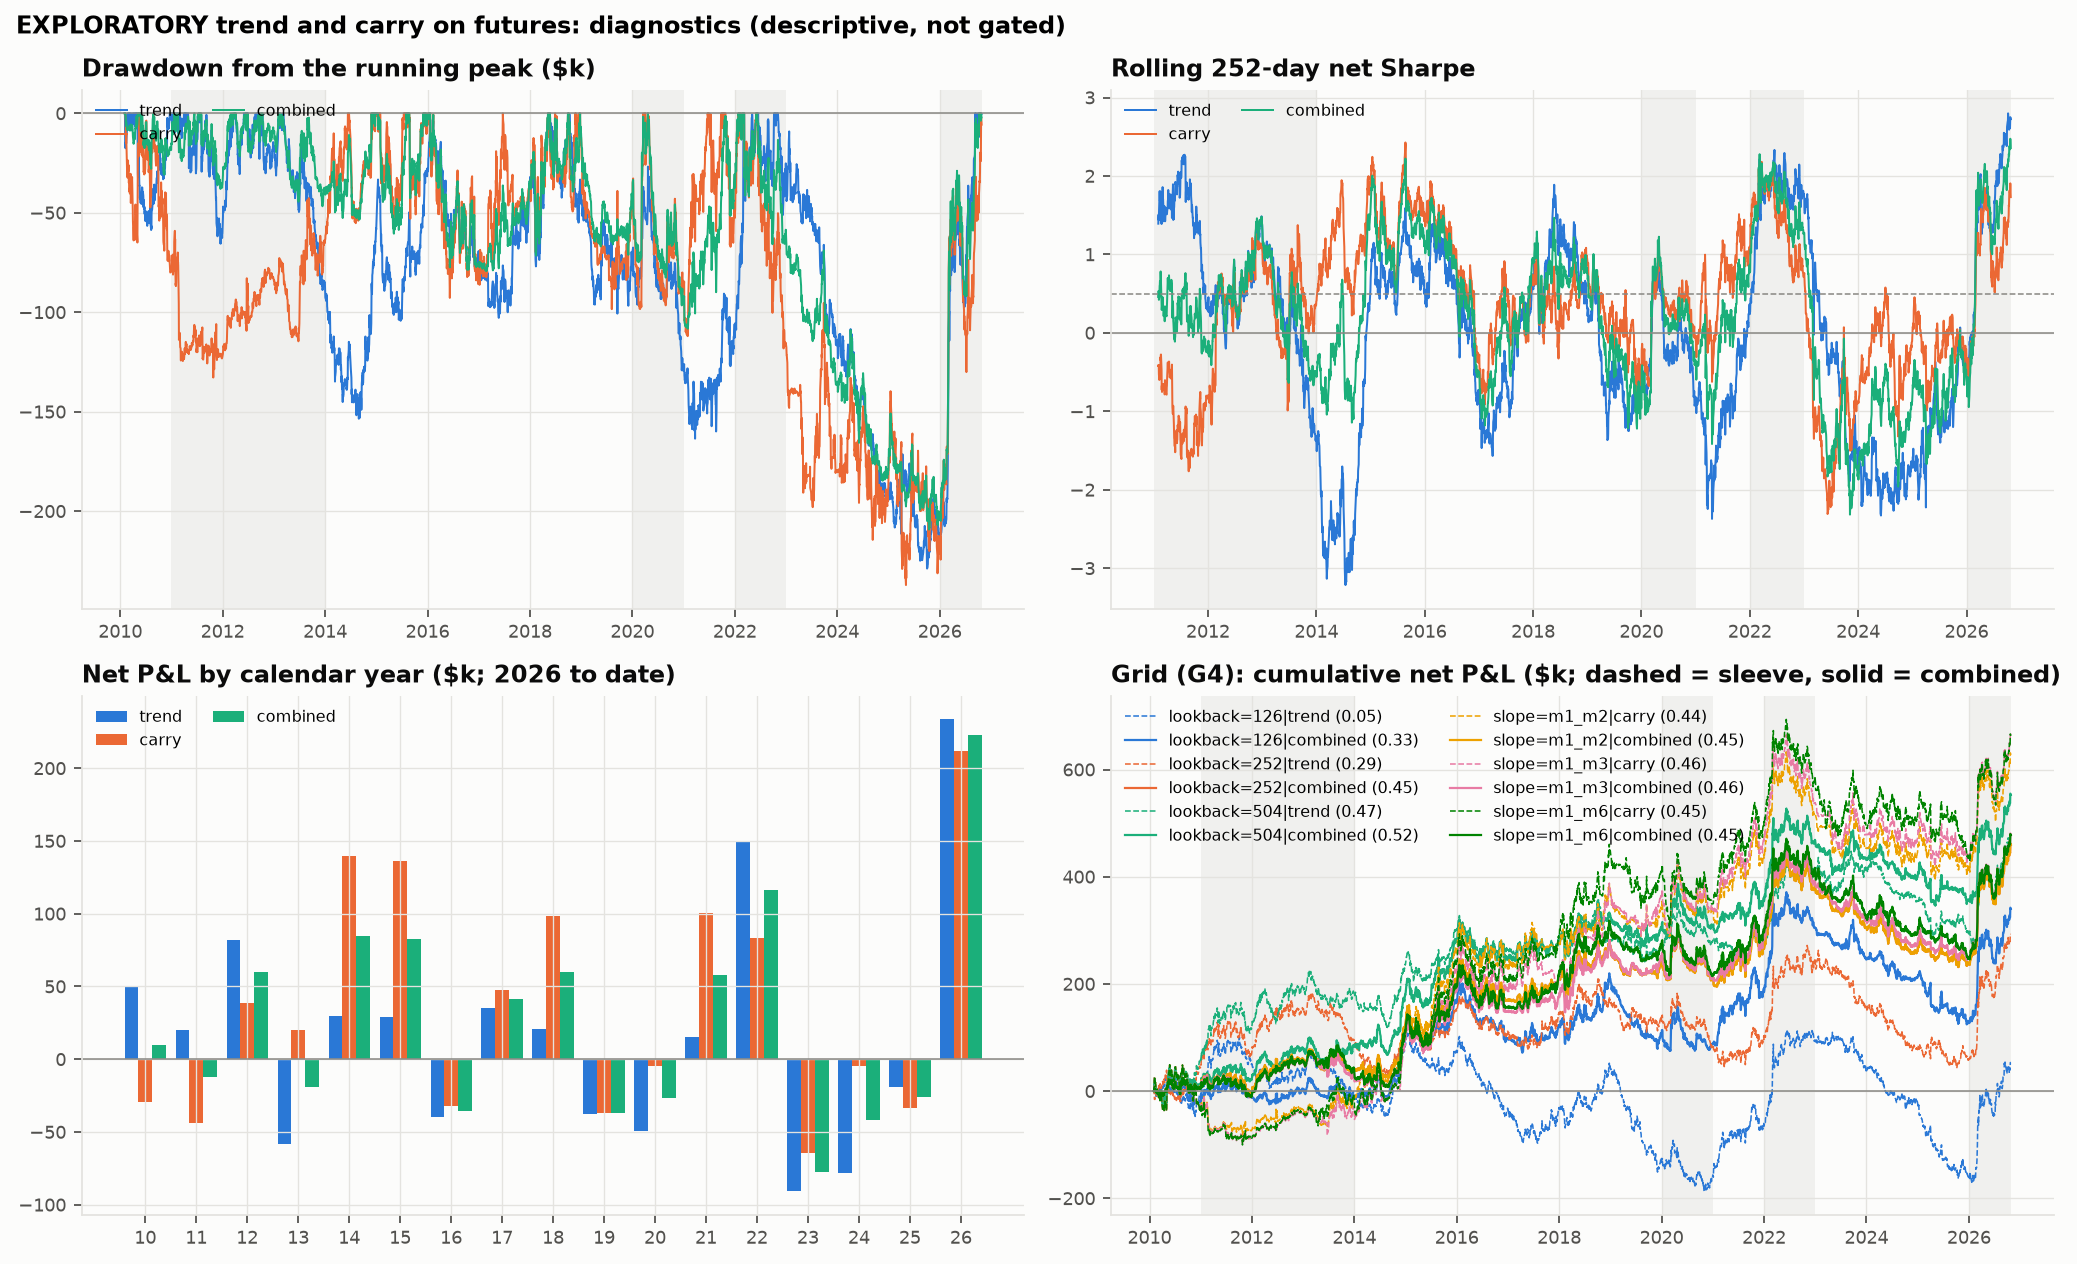

In [9]:
Image(str(F / 'diagnostics.png'))

In [10]:
a = read('annual.csv', header=[0, 1], index_col=0)
a.index.name = 'year'
out = (a['net'] / 1e3).round(1).add_suffix(' net $k').join(a['sharpe'].round(2).add_suffix(' Sharpe'))
print('positive years (combined):', int((a['net']['combined'] > 0).sum()), 'of', len(a))
out

positive years (combined): 9 of 17


,trend net $k,carry net $k,combined net $k,trend Sharpe,carry Sharpe,combined Sharpe
year,,,,,,
2010,49.3,-29.2,10.1,1.03,-0.36,0.27
2011,20.2,-44.0,-11.9,0.29,-0.83,-0.26
2012,81.9,38.3,60.1,1.37,1.07,1.38
2013,-58.4,20.3,-19.0,-1.35,0.40,-0.49
2014,29.8,139.9,84.9,0.55,1.92,1.54
2015,28.9,135.9,82.4,0.54,1.44,1.13
2016,-39.7,-32.0,-35.9,-0.74,-0.34,-0.51
2017,35.0,47.8,41.4,0.61,0.73,0.95
2018,20.9,98.4,59.7,0.31,0.95,0.76


In [11]:
read('drawdowns.csv', index_col=[0, 1]).assign(depth=lambda d: (d['depth'] / 1e3).round(1)).rename(columns={'depth': 'depth $k'})

peak      trough   recovered  depth $k  days_to_trough  days_underwater
book     rank                                                                               
trend    0     2022-11-04  2025-10-02  2026-09-10    -228.8             729            964.0
         1     2018-10-03  2021-03-23  2022-03-07    -163.5             621            862.0
         2     2013-03-08  2014-08-29  2018-05-09    -153.5             373           1302.0
         3     2011-07-20  2011-12-19  2012-03-23     -65.4             106            171.0
         4     2010-05-03  2010-08-09  2010-12-20     -58.6              68            160.0
carry    0     2022-06-08  2025-05-05         NaN    -237.1             729              NaN
         1     2010-05-25  2011-10-26  2014-06-12    -132.8             359           1020.0
         2     2020-04-21  2021-01-29  2021-06-21    -112.0             196            294.0
         3     2018-12-24  2019-08-07  2020-03-18     -98.4             155            309.0
         4     2016-01-20  2016-06-08  2017-06-21     -92.8              97            358.0
combined 0     2022-06-09  2025-10-16  2026-10-12    -209.2             842           1089.0
         1     2020-04-21  2021-01-29  2022-01-26    -108.3             196            446.0
         2     2016-01-20  2017-02-21  2018-05-09     -79.2             274            580.0
         3     2018-12-24  2020-02-14  2020-04-20     -74.9             287            331.0
         4     2015-01-13  2015-05-06  2015-08-03     -60.5              78            139.0

- **The profit comes in bursts.** The combined book made money in 9 of 17 calendar years. Most of the gain came in 2014–15, 2021–22 and 2026.
- **The worst stretch was 2023–25,** when all three books lost every year (combined −\$145k over the three years). The 1-year rolling Sharpe stayed below zero for most of it.
- **Long recoveries.** The combined book's deepest drawdown, −\$209k, ran from a peak on 9 Jun 2022 to a trough on 16 Oct 2025, and recovered only on 12 Oct 2026. The carry sleeve has still not regained its June 2022 peak.
- **Takeaway:** a live trader would have had to hold through about three years underwater.

## Costs

In [12]:
(read('cost_breakdown.csv', index_col=0)).round(3)

,gross,cost,roll,pnl,cost_share_of_gross
sleeve,,,,,
carry,700071.148,63699.204,8995.443,627376.501,0.104
trend,478508.788,164335.886,21486.249,292686.653,0.388


- **Trend pays 39% of its gross profit in costs, carry 10%.** Both sleeves resize every day, and the trend sleeve holds the low-volatility spreads.
- **Brent–WTI is the extreme case.** Its σ̂ is often under \$0.50/bbl, so it carries 10+ contracts a leg and pays \$586k of its \$1.05m gross.
- **Rebalancing less often would probably cut this,** but that would be a new, separately registered test.

## Diversification against the registered mean-reversion strategy (descriptive)

In [13]:
read('correlation_with_mean_reversion.csv', index_col=0)

,trend,carry,combined,mean_reversion
trend,1.000,0.424,0.784,-0.218
carry,0.424,1.000,0.895,0.013
combined,0.784,0.895,1.000,-0.098
mean_reversion,-0.218,0.013,-0.098,1.000


Daily P&L correlation with the registered mean-reversion research stream (futures, gated, three spreads summed):
- trend −0.22
- carry 0.01
- combined −0.10

Trend and carry look like a **complement** to mean reversion, not a replacement: they make money in the persistent moves that hurt it. Testing the two books together would be a new registration.

## Signals

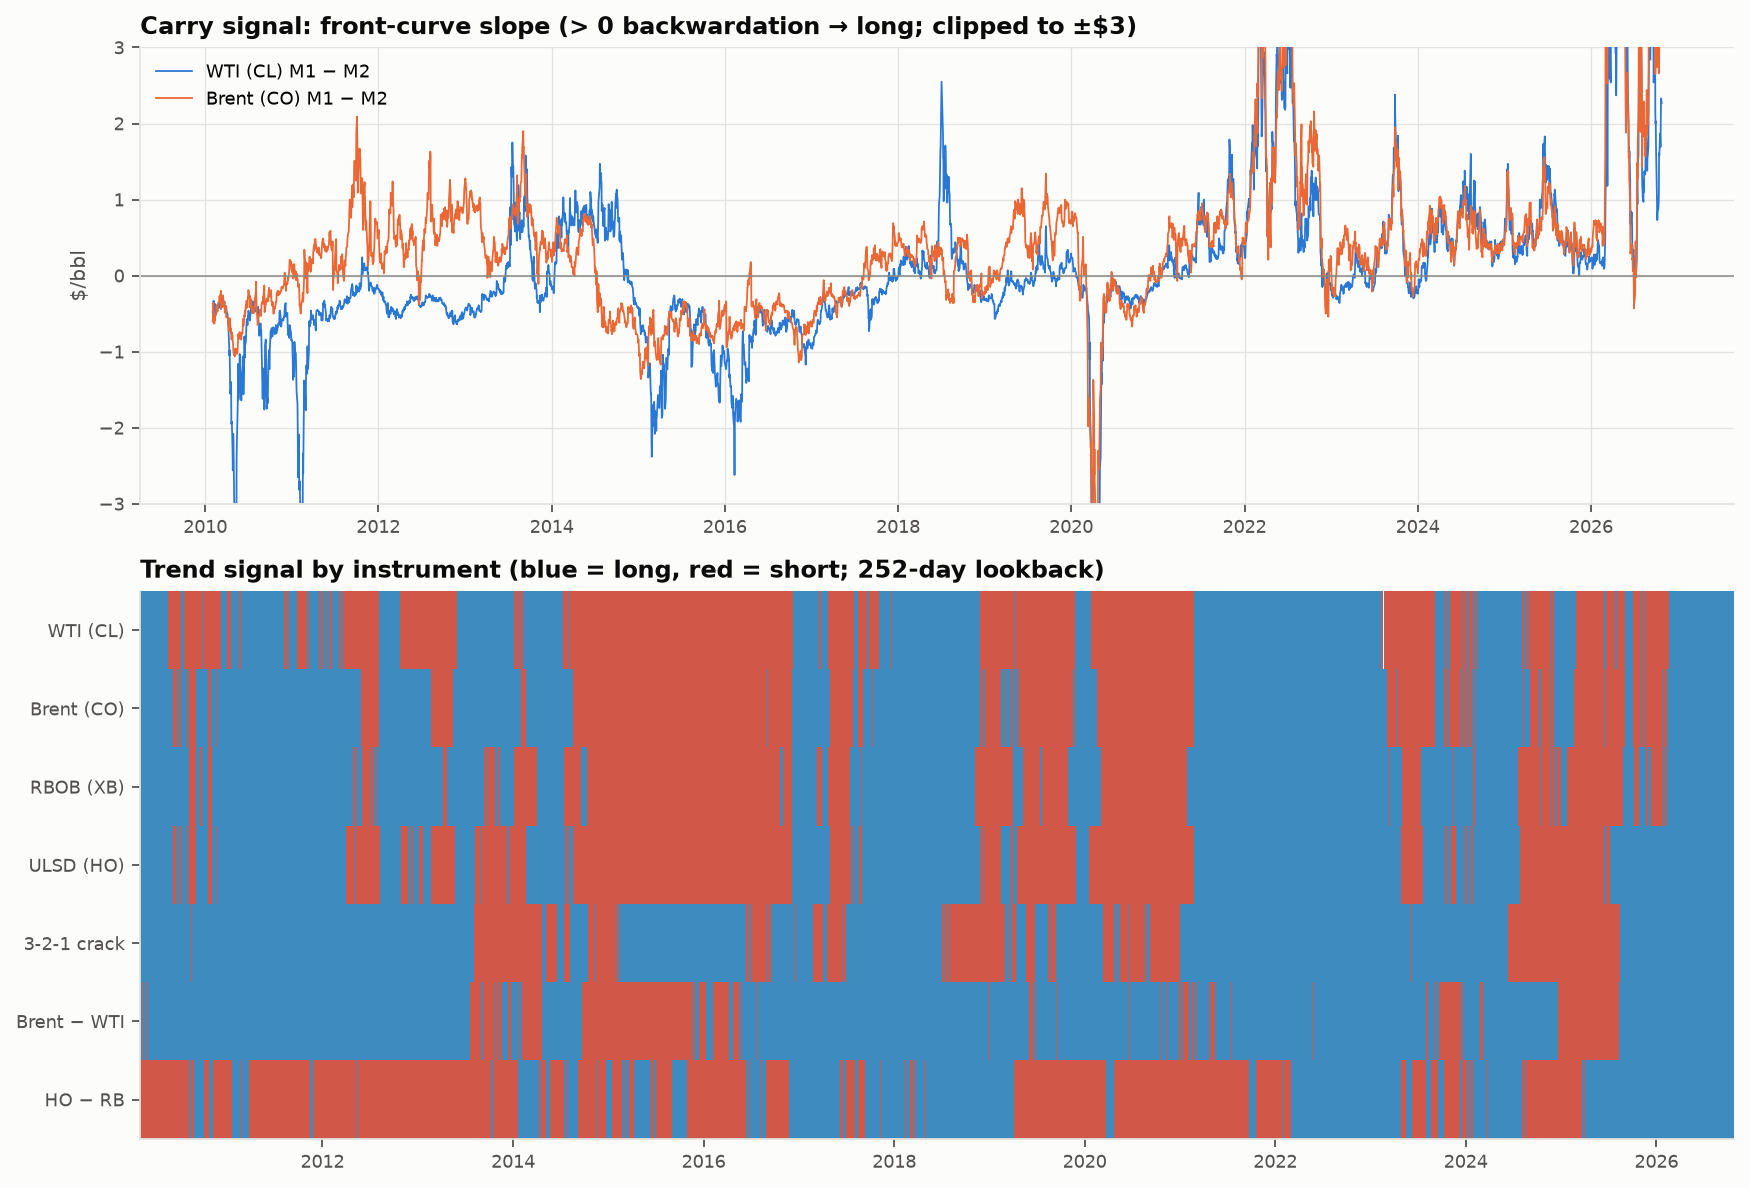

In [14]:
Image(str(F / 'signals.png'))

**Carry (top).**
- WTI was in contango for most of 2010–17. That was the era of the Cushing glut, and it set WTI carry against Brent carry in 2010–13.
- Both curves have been mostly backwardated since 2021, and steeply so in 2022 and 2026.

**Trend (bottom).**
- The outrights flip together, at the 2014 collapse, in 2019–20 and in 2023.
- The spreads have their own cycles.

## Today's book (as of the last close)

In [15]:
read('current_book.csv', index_col=0)

,date,signal,direction,sigma_usd_bbl,target_units,held_units,contracts
trend|cl,2026-10-26,1.0,long,2.033345,2.950803,3.256549,CL +2.95
trend|brent,2026-10-26,1.0,long,2.291256,2.618651,2.666852,BRENT +2.62
trend|rb,2026-10-26,1.0,long,2.435891,2.463165,2.301058,RB +2.46
trend|ho,2026-10-26,1.0,long,4.640664,1.292918,1.202613,HO +1.29
trend|crack321,2026-10-26,1.0,long,2.026832,0.986762,0.926281,"CL -2.96, RB +1.97, HO +0.99"
trend|brent_wti,2026-10-26,1.0,long,0.371391,16.155494,16.155494,"BRENT +16.16, CL -16.16"
trend|ho_rb,2026-10-26,1.0,long,4.340087,1.382461,1.265372,"HO +1.38, RB -1.38"
carry|cl,2026-10-26,1.0,long,2.033345,2.950803,3.256549,CL +2.95
carry|brent,2026-10-26,1.0,long,2.291256,2.618651,2.666852,BRENT +2.62


**Every instrument is long at the last close (26 Oct 2026).**
- Trend is long all seven instruments, and both curves are backwardated, so carry is long WTI and Brent.
- With all nine positions pointing the same way, the book is in effect one leveraged long-oil bet.
- At the instrument level, the Brent–WTI trend position is 16 contracts a leg. That is because its σ̂ is only \$0.37/bbl.
- The units are research units at R = \$6k a day per instrument, before the 0.5 sleeve weights and the averaging inside each sleeve. They are not an integer trading book.

## Reconciliation

The books are rebuilt from the saved per-instrument daily paths (`data/derived/exploratory/trend_carry_daily.csv`). The check also confirms the fill timing: the position held over (t−1, t] is the target decided at t−2.

In [16]:
p = pd.read_csv(ROOT / 'data/derived/exploratory/trend_carry_daily.csv', parse_dates=['date'])
books = read('daily_books.csv', index_col=0, parse_dates=True)
rebuilt = p.pivot_table(index=['date'], columns=['sleeve', 'instrument'], values='pnl').T.groupby(level=0).mean().T
rebuilt['combined'] = 0.5 * rebuilt['trend'] + 0.5 * rebuilt['carry']
lag_ok = all(np.allclose(g['pos'].iloc[2:].to_numpy(), g['target'].iloc[:-2].to_numpy())
             for _, g in p.groupby(['sleeve', 'instrument']))
ident = np.allclose(p['pnl'], p['gross'] - p['cost'] - p['roll'])
print('books rebuilt from paths match:', np.allclose(rebuilt[books.columns], books))
print('pos = target two closes earlier:', lag_ok, '| pnl = gross − cost − roll:', ident)
print('instruments × days:', p.groupby(['sleeve', 'instrument']).size().to_dict())

books rebuilt from paths match: True
pos = target two closes earlier: True | pnl = gross − cost − roll: True
instruments × days: {('carry', 'brent'): 4213, ('carry', 'cl'): 4213, ('trend', 'brent'): 4213, ('trend', 'brent_wti'): 4213, ('trend', 'cl'): 4213, ('trend', 'crack321'): 4213, ('trend', 'ho'): 4213, ('trend', 'ho_rb'): 4213, ('trend', 'rb'): 4213}


## Conclusions
1. **Verdict: FAIL (exploratory).** The combined book misses G1 by 0.05 and passes G2–G5. The pre-registered mean-reversion verdict stands.
2. **Carry is the stronger and steadier signal.** Trend is uneven across instruments and sensitive to the lookback.
3. **It complements mean reversion.** Its daily P&L is negatively correlated with the mean-reversion stream, and it made money in 2022 and 2026.
4. **The weaknesses are practical.** Returns come in bursts, with a three-year drawdown in 2023–25. Costs are heavy on the low-volatility spreads. All nine instruments are oil, so they offer little diversification.
5. **Any next step needs its own pre-registration first.** Candidates:
   - less frequent rebalancing
   - a combined overlay with mean reversion
   - forward paper trading with today's rules

Full write-up: `report/exploratory_trend_carry.md`.